In [21]:
import numpy as np

In [22]:

class Bandit:
    def __init__(self,arms=10):
        self.rates=np.random.rand(arms)
    def play(self,arm):
        rate=self.rates[arm]
        if rate>np.random.rand():
            return 1
        else:
            return 0

    


In [23]:
bandit=Bandit()  
for i in range(3):
    print(bandit.play(0))
        

1
1
1


In [24]:
bandit=Bandit()
Q=0
for n in range(1,11):
    reward=bandit.play(0)
    Q+=(reward-Q)/n
    print(Q)

0.0
0.0
0.0
0.0
0.0
0.0
0.14285714285714285
0.125
0.1111111111111111
0.09999999999999999


In [25]:
bandit=Bandit()
Qs=np.zeros(10)
ns=np.zeros(10)
for n in range(1,11):
    action=np.random.randint(10)
    reward=bandit.play(action)
    ns[action]+=1
    Qs[action]+=(reward-Qs[action])/ns[action]
    print(Qs)

[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
[0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
[0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
[0.  0.  0.  0.  0.  0.  0.  0.  0.  0.5]
[0.  0.  0.  0.  0.  0.  0.  0.  0.  0.5]
[0.  0.  0.  0.  0.  0.  0.  0.  0.  0.5]
[0.  0.  0.  0.  0.  0.  0.  0.  0.  0.5]
[0.   0.   0.   0.25 0.   0.   0.   0.   0.   0.5 ]


In [26]:
class Agent:
    def __init__(self,epsilon,action_size=10):
        self.epsilon=epsilon
        self.Qs=np.zeros(action_size)
        self.ns=np.zeros(action_size)

    def update(self,action,reward):
        self.ns[action]+=1
        self.Qs[action]+=(reward-self.Qs[action])/self.ns[action]

    def get_action(self):
        if np.random.rand()<self.epsilon:
            return np.random.randint(0,len(self.Qs))
        return np.argmax(self.Qs)
    

In [27]:
import matplotlib.pyplot as plt


913


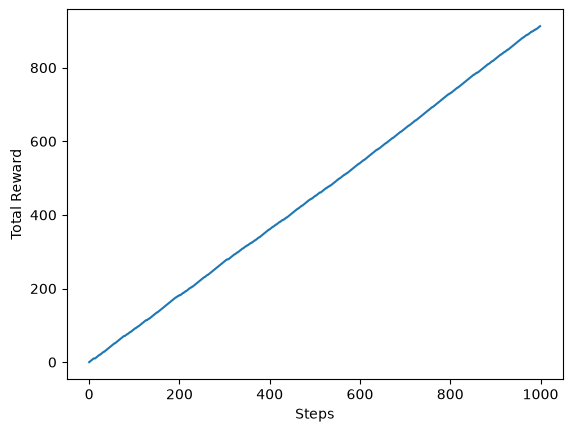

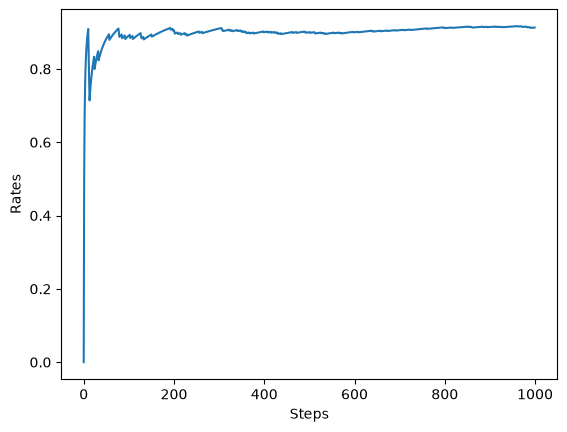

In [28]:
steps=1000
epsilon=0.1

bandit=Bandit()
agent=Agent(epsilon)
total_reward=0
total_rewards=[]
rates=[]

for step in range(steps):
    action=agent.get_action()
    reward=bandit.play(action)
    agent.update(action,reward)
    total_reward+=reward

    total_rewards.append(total_reward)
    rates.append(total_reward/(step+1))

print(total_reward)

plt.ylabel('Total Reward')
plt.xlabel('Steps')
plt.plot(total_rewards)
plt.show()

plt.ylabel('Rates')
plt.xlabel('Steps')
plt.plot(rates)
plt.show()





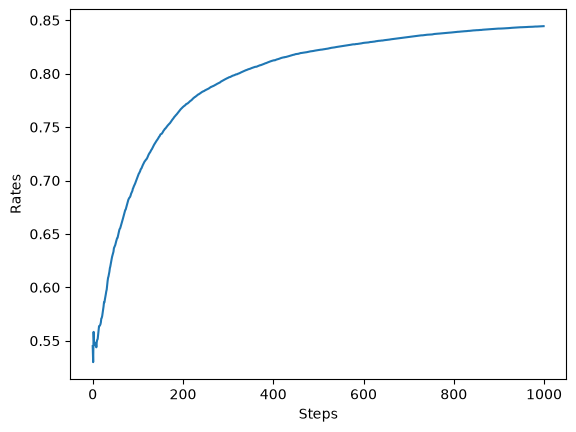

In [46]:
runs=200
steps=1000
epsilon=0.1
all_rates=np.zeros((runs, steps))

for run in range(runs):
    bandit=Bandit()
    agent=Agent(epsilon)
    total_reward=0
    rates=[]
    for step in range(steps):
        action=agent.get_action()
        reward=bandit.play(action)
        agent.update(action,reward)
        total_reward+=reward
        rates.append(total_reward/(step+1))
    all_rates[run]=rates
average_rates=np.mean(all_rates,axis=0)
plt.ylabel('Rates')
plt.xlabel('Steps')
plt.plot(average_rates)
plt.show()



In [34]:
class NonStatBanit:
    def __init__(self,arms=10):
        self.arms=arms
        self.rates=np.random.rand(arms)

    def play(self,arm):
        rate=self.rates[arm]
        self.rates+=0.1*np.random.randn(self.arms)
        if rate>np.random.rand():
            return 1
        else:
            return 0
            
        


In [35]:
class AlphaAgent:
    def __init__(self,epsilon,alpha,actions=10):
        self.epsilon=epsilon
        self.Qs=np.zeros(actions)
        self.alpha=alpha

    def update(self,action,reward):
        self.Qs[action]+=(reward-self.Qs[action])*self.alpha

    def get_action(self):
        if np.random.rand()<self.epsilon:
            return np.random.randint(0,len(self.Qs))
        return np.argmax(self.Qs)


960


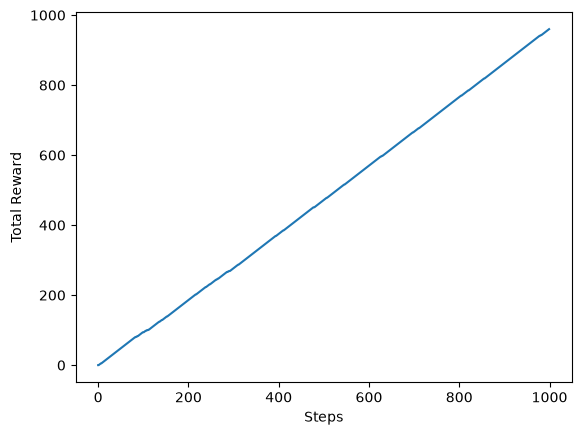

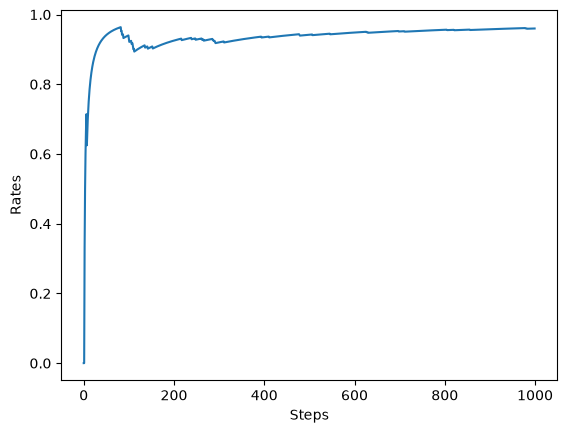

In [37]:
steps=1000
epsilon=0.1
alpha=0.8

nonstatbandit=NonStatBanit()
alphaagent=AlphaAgent(epsilon,alpha)
total_reward=0
total_rewards=[]
rates=[]

for step in range(steps):
    action=alphaagent.get_action()
    reward=nonstatbandit.play(action)
    alphaagent.update(action,reward)
    total_reward+=reward
    total_rewards.append(total_reward)
    rates.append(total_reward/(step+1))

print(total_reward)

plt.ylabel('Total Reward')
plt.xlabel('Steps')
plt.plot(total_rewards)
plt.show()

plt.ylabel('Rates')
plt.xlabel('Steps')
plt.plot(rates)
plt.show()

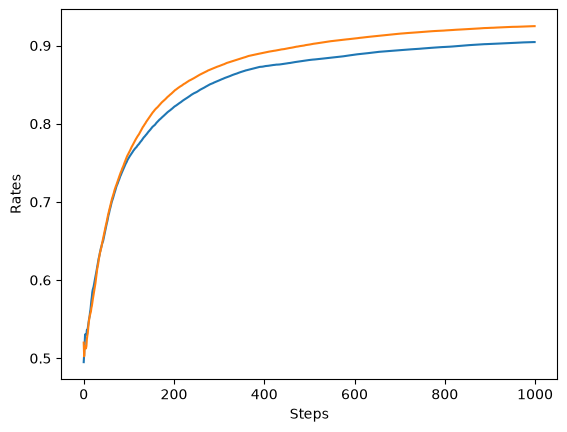

In [51]:
runs=200
steps=1000
epsilon=0.1
alpha=0.8
all_rates_alpha1=np.zeros((runs, steps))
all_rates_alpha2=np.zeros((runs, steps))
for run in range(runs):
    nonstatbandit=NonStatBanit()
    agent=Agent(epsilon)
    total_reward=0
    rates=[]
    for step in range(steps):
        action=agent.get_action()
        reward=nonstatbandit.play(action)
        agent.update(action,reward)
        total_reward+=reward
        rates.append(total_reward/(step+1))
    all_rates_alpha1[run]=rates
average_rates_av=np.mean(all_rates_alpha1,axis=0)

for run in range(runs):
    nonstatbandit=NonStatBanit()
    alphaagent=AlphaAgent(epsilon,alpha)
    total_reward=0
    rates=[]
    for step in range(steps):
        action=alphaagent.get_action()
        reward=nonstatbandit.play(action)
        alphaagent.update(action,reward)
        total_reward+=reward
        rates.append(total_reward/(step+1))
    all_rates_alpha2[run]=rates
average_rates_alpha=np.mean(all_rates_alpha2,axis=0)


plt.ylabel('Rates')
plt.xlabel('Steps')
plt.plot(average_rates_av)
plt.plot(average_rates_alpha)
plt.show()

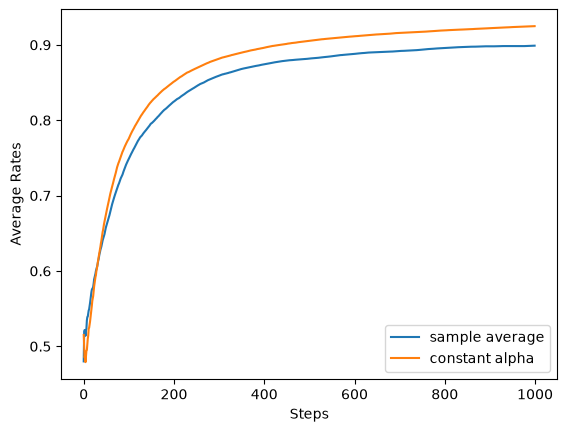

In [43]:
runs = 200
steps = 1000
epsilon = 0.1
alpha = 0.8
results = {}

for method in ['sample average', 'constant alpha']:
    all_rates = np.zeros((runs, steps))

    for run in range(runs):
        bandit = NonStatBanit()
        agent = (
            Agent(epsilon)
            if method == 'sample average'
            else AlphaAgent(epsilon, alpha)
        )
        total_reward = 0

        for step in range(steps):
            action = agent.get_action()
            reward = bandit.play(action)
            agent.update(action, reward)

            total_reward += reward
            all_rates[run, step] = total_reward / (step + 1)

    results[method] = np.mean(all_rates, axis=0)

for method, rates in results.items():
    plt.plot(rates, label=method)

plt.xlabel('Steps')
plt.ylabel('Average Rates')
plt.legend()
plt.show()